# s3 — predicting multi-skip collapse from single skips

**Question:** if we know the accuracy damage of skipping block *a* alone, and block *b* alone, can we predict the damage of skipping both — as one contiguous 2-block span, or as two disjoint single-block skips?

Three predictors of multi-skip damage, all built from single-skip drops:

- **naive** — sum of single-skip drops, no fitting: `predicted = drop(a) + drop(b)`
- **cka** — naive sum + a learned local-CKA correction term, fit per (model, dataset)
- **angdist** — naive sum + a learned angular-distance correction term, fit per (model, dataset)

Each is scored by **Pearson r** (does it track the *magnitude* of damage?) and **Spearman rank r** (does it correctly *rank* skips from safest to most damaging?), against the actual measured multi-skip damage. Checked separately for **contiguous** (2-block spans) and **disjoint** (two separate single-block skips) shapes, then we stratify the disjoint case by the gap between the two skips.

Inputs:

- `accuracies/combined/accuracies_results_*_contiguous.csv` — contiguous 2-block spans (from the s2 sweep)
- `accuracies/combined/accuracies_results_*_disjoint.csv` — disjoint pairs (the s3 sweep, ImageNet-1k only)
- `analysis/cka_angular_1_2_layer_spans.csv` — local CKA, angular distance and accuracy for every 1- and 2-layer span (the single-skip drops come from its 1-layer rows)
- `../s2_skip_cost_metrics/accuracies/accuracies_results_*.csv` — only for the unskipped baseline accuracy

Spans are written as in the configs: `(s, e)` bridges hidden state `s` to hidden state `e`, so `(s, s+1)` skips one block and `(s, s+2)` skips two. A contiguous span `(s, s+2)` is the union of the single skips `(s, s+1)` and `(s+1, s+2)`.

In [69]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

S3 = Path.cwd().resolve()
if S3.name == "analysis":
    S3 = S3.parent
S2 = S3.parent / "s2_skip_cost_metrics"
ANALYSIS, FIG_DIR = S3 / "analysis", S3 / "figures"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

MODELS = {"deitsmall": "DeiT-S", "vitsmall": "ViT-S", "dinov2base": "DINOv2-B", "vitlarge": "ViT-L"}
DATASETS = {"cifar100": "CIFAR-100", "imagenet1k": "ImageNet-1k"}
PREDICTORS = ["naive", "cka", "angdist"]

## Load

`span_metrics` is the per-span table of local CKA, angular distance and accuracy for every 1- and 2-layer span; its 1-layer rows give the single-skip drops. `contiguous_acc` / `disjoint_acc` are the combined 2-block sweeps. Only the unskipped baseline accuracy is read from s2.

In [70]:
def parse_spans(approx_layer):
    return tuple(tuple(s) for s in ast.literal_eval(approx_layer))


# Local CKA / angular distance (and accuracy) for every 1- and 2-layer span
span_metrics = pd.read_csv(ANALYSIS / "cka_angular_1_2_layer_spans.csv")
span_metrics["span_t"] = list(zip(span_metrics["start"], span_metrics["end"]))
span_key = list(zip(span_metrics["model"], span_metrics["dataset"], span_metrics["span_t"]))
CKA = dict(zip(span_key, span_metrics["local_cka"]))
ANG = dict(zip(span_key, span_metrics["angular_dist"]))

# The unskipped baseline is the one number not in the s3 folder
baselines = {}
for model in MODELS:
    for tag in DATASETS:
        acc = pd.read_csv(S2 / "accuracies" / f"accuracies_results_{model}_{tag}.csv")
        baselines[(model, tag)] = acc.loc[acc["approx_layer"] == "[]", "accuracy_mean"].iloc[0]


def load_combined(shape):
    frames = []
    for model in MODELS:
        for tag in DATASETS:
            path = S3 / "accuracies" / "combined" / f"accuracies_results_{model}_{tag}_{shape}.csv"
            if path.exists():
                acc = pd.read_csv(path)[["approx_layer", "accuracy_mean", "accuracy_std"]]
                frames.append(acc.assign(model=model, dataset=tag))
    out = pd.concat(frames, ignore_index=True)
    out["spans"] = out["approx_layer"].map(parse_spans)
    return out


contiguous_acc = load_combined("contiguous")
disjoint_acc = load_combined("disjoint")

single_acc = span_metrics[span_metrics["width"] == 1].rename(columns={"true_accuracy": "accuracy_mean"})
single_acc = single_acc.assign(spans=single_acc["span_t"].map(lambda sp: (sp,)),
                               approx_layer=single_acc["span_t"].map(lambda sp: str([sp])))

for frame in (single_acc, contiguous_acc, disjoint_acc):
    frame["delta_acc"] = [baselines[(m, d)] - a for m, d, a in zip(frame["model"], frame["dataset"], frame["accuracy_mean"])]

single_drop = {(m, d, sp[0]): x for m, d, sp, x in zip(single_acc["model"], single_acc["dataset"], single_acc["spans"], single_acc["delta_acc"])}

pd.DataFrame({
    "baseline_acc": pd.Series(baselines),
    "single": single_acc.groupby(["model", "dataset"]).size(),
    "contiguous": contiguous_acc.groupby(["model", "dataset"]).size(),
    "disjoint": disjoint_acc.groupby(["model", "dataset"]).size(),
}).fillna(0).astype({"single": int, "contiguous": int, "disjoint": int})

baseline_acc  single  contiguous  disjoint
deitsmall  cifar100           0.712      11          10         0
           imagenet1k         0.738      11          10        45
dinov2base cifar100           0.870      11          10         0
           imagenet1k         0.748      11          10        45
vitlarge   cifar100           0.858      23          22         0
           imagenet1k         0.786      23          22       231
vitsmall   cifar100           0.819      11          10         0
           imagenet1k         0.736      11          10        45

In [71]:
single_acc.head(3)

,model,dataset,span,start,end,width,local_cka,cka_embed,angular_dist,accuracy_mean,span_t,spans,approx_layer,delta_acc
0,deitsmall,cifar100,"(0,1)",0,1,1,0.842,0.205,0.229,0.620,"(0, 1)","((0, 1),)","[(0, 1)]",0.093
1,deitsmall,cifar100,"(1,2)",1,2,1,0.891,0.313,0.221,0.643,"(1, 2)","((1, 2),)","[(1, 2)]",0.070
2,deitsmall,cifar100,"(2,3)",2,3,1,0.791,0.404,0.182,0.698,"(2, 3)","((2, 3),)","[(2, 3)]",0.015


In [72]:
contiguous_acc.head(3)

,approx_layer,accuracy_mean,accuracy_std,model,dataset,spans,delta_acc
0,"[(0, 2)]",0.485,0.003,deitsmall,cifar100,"((0, 2),)",0.228
1,"[(1, 3)]",0.619,0.000,deitsmall,cifar100,"((1, 3),)",0.093
2,"[(2, 4)]",0.668,0.002,deitsmall,cifar100,"((2, 4),)",0.045


In [73]:
disjoint_acc.head(3)

,approx_layer,accuracy_mean,accuracy_std,model,dataset,spans,delta_acc
0,"[(0, 1), (2, 3)]",0.587,0.003,deitsmall,imagenet1k,"((0, 1), (2, 3))",0.151
1,"[(1, 2), (3, 4)]",0.668,0.002,deitsmall,imagenet1k,"((1, 2), (3, 4))",0.070
2,"[(2, 3), (4, 5)]",0.698,0.004,deitsmall,imagenet1k,"((2, 3), (4, 5))",0.040


In [74]:

for model in MODELS:
    for dataset in DATASETS:
        df = contiguous_acc[(contiguous_acc["model"] == model) & (contiguous_acc["dataset"] == dataset)]
        true_delta_accs = []
        naive_delta_accs = []
        for i in range(0, 9):
                end = i + 2
                span = (i, end)
                df_row = df[df["spans"].map(lambda sp: sp == (span,))]
                if not df_row.empty:
                    cka = CKA[(model, dataset, span)]
                    ang = ANG[(model, dataset, span)]
                    delta_acc = df_row["delta_acc"].iloc[0]
                first_skip = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset) & (single_acc["start"] == i)]
                second_skip = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset) & (single_acc["start"] == i+1)]
                first_skip_delta_acc = first_skip["delta_acc"].iloc[0] if not first_skip.empty else np.nan
                second_skip_delta_acc = second_skip["delta_acc"].iloc[0] if not second_skip.empty else np.nan
                naive_delta_acc = first_skip_delta_acc + second_skip_delta_acc
                true_delta_acc = delta_acc
                naive_delta_accs.append(naive_delta_acc)
                true_delta_accs.append(true_delta_acc)
        spearman = spearmanr(naive_delta_accs, true_delta_accs)
        pearson = pearsonr(naive_delta_accs, true_delta_accs)
        
        print(f"{MODELS[model]} {DATASETS[dataset]}: Spearman correlation between naive and true delta_accs: {spearman.correlation:.3f} (p={spearman.pvalue:.3f})")
        print(f"{MODELS[model]} {DATASETS[dataset]}: Pearson correlation between naive and true delta_accs: {pearson.correlation:.3f} (p={pearson.pvalue:.3f})")

DeiT-S CIFAR-100: Spearman correlation between naive and true delta_accs: 1.000 (p=0.000)
DeiT-S CIFAR-100: Pearson correlation between naive and true delta_accs: 0.988 (p=0.000)
DeiT-S ImageNet-1k: Spearman correlation between naive and true delta_accs: 0.950 (p=0.000)
DeiT-S ImageNet-1k: Pearson correlation between naive and true delta_accs: 0.970 (p=0.000)
ViT-S CIFAR-100: Spearman correlation between naive and true delta_accs: 0.983 (p=0.000)
ViT-S CIFAR-100: Pearson correlation between naive and true delta_accs: 0.847 (p=0.004)
ViT-S ImageNet-1k: Spearman correlation between naive and true delta_accs: 0.900 (p=0.001)
ViT-S ImageNet-1k: Pearson correlation between naive and true delta_accs: 0.892 (p=0.001)
DINOv2-B CIFAR-100: Spearman correlation between naive and true delta_accs: 0.900 (p=0.001)
DINOv2-B CIFAR-100: Pearson correlation between naive and true delta_accs: 0.784 (p=0.012)
DINOv2-B ImageNet-1k: Spearman correlation between naive and true delta_accs: 0.700 (p=0.036)
DIN

In [75]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict

contiguous_results = pd.DataFrame(columns=["model", "dataset", "metric", "spearman_corr", "spearman_pval", "pearson_corr", "pearson_pval"])
for model in MODELS:
    for dataset in DATASETS:
        df = contiguous_acc[(contiguous_acc["model"] == model) & (contiguous_acc["dataset"] == dataset)].copy()
        single_delta = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset)].set_index("start")["delta_acc"]

        df["start"] = df["spans"].map(lambda sp: sp[0][0])
        df["naive"] = df["start"].map(single_delta) + (df["start"] + 1).map(single_delta)
        df["cka"] = [CKA[(model, dataset, sp[0])] for sp in df["spans"]]
        df["ang"] = [ANG[(model, dataset, sp[0])] for sp in df["spans"]]
        df = df.dropna(subset=["naive"])

        # naive: no fitting. cka / ang: OLS delta_acc ~ intercept + metric + naive, scored on leave-one-out predictions
        predictions = {"naive": df["naive"]}
        for metric in ["cka", "ang"]:
            predictions[metric] = cross_val_predict(LinearRegression(), df[[metric, "naive"]], df["delta_acc"], cv=LeaveOneOut())

        for name, pred in predictions.items():
            spearman = spearmanr(pred, df["delta_acc"])
            pearson = pearsonr(pred, df["delta_acc"])
            print(f"{MODELS[model]} {DATASETS[dataset]} [{name}]: "
                  f"Spearman {spearman.statistic:.3f} (p={spearman.pvalue:.3f}), "
                  f"Pearson {pearson.statistic:.3f} (p={pearson.pvalue:.3f})")
            contiguous_results_row = {
                "model": model,
                "dataset": dataset,
                "metric": name,
                "spearman_corr": spearman.statistic,
                "spearman_pval": spearman.pvalue,
                "pearson_corr": pearson.statistic,
                "pearson_pval": pearson.pvalue
            }
            contiguous_results = pd.concat([contiguous_results, pd.DataFrame([contiguous_results_row])], ignore_index=True)


DeiT-S CIFAR-100 [naive]: Spearman 1.000 (p=0.000), Pearson 0.989 (p=0.000)
DeiT-S CIFAR-100 [cka]: Spearman 0.927 (p=0.000), Pearson 0.955 (p=0.000)
DeiT-S CIFAR-100 [ang]: Spearman 1.000 (p=0.000), Pearson 0.953 (p=0.000)
DeiT-S ImageNet-1k [naive]: Spearman 0.964 (p=0.000), Pearson 0.969 (p=0.000)
DeiT-S ImageNet-1k [cka]: Spearman 0.939 (p=0.000), Pearson 0.889 (p=0.001)
DeiT-S ImageNet-1k [ang]: Spearman 0.976 (p=0.000), Pearson 0.914 (p=0.000)
ViT-S CIFAR-100 [naive]: Spearman 0.988 (p=0.000), Pearson 0.854 (p=0.002)
ViT-S CIFAR-100 [cka]: Spearman 0.891 (p=0.001), Pearson 0.686 (p=0.028)
ViT-S CIFAR-100 [ang]: Spearman 0.915 (p=0.000), Pearson 0.687 (p=0.028)
ViT-S ImageNet-1k [naive]: Spearman 0.927 (p=0.000), Pearson 0.909 (p=0.000)
ViT-S ImageNet-1k [cka]: Spearman 0.879 (p=0.001), Pearson 0.872 (p=0.001)
ViT-S ImageNet-1k [ang]: Spearman 0.830 (p=0.003), Pearson 0.855 (p=0.002)
DINOv2-B CIFAR-100 [naive]: Spearman 0.915 (p=0.000), Pearson 0.796 (p=0.006)
DINOv2-B CIFAR-100 [

/var/folders/qw/dj7vjbyd6kb8q83q6chjb9m00000gn/T/ipykernel_18506/4211438407.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  contiguous_results = pd.concat([contiguous_results, pd.DataFrame([contiguous_results_row])], ignore_index=True)


In [76]:
contiguous_results.groupby(["metric"]).agg({"spearman_corr": ["median", "std"], "pearson_corr": ["median", "std"]})

spearman_corr       pearson_corr      
              median   std       median   std
metric                                       
ang            0.818 0.224        0.683 0.269
cka            0.788 0.195        0.604 0.243
naive          0.941 0.088        0.860 0.069

Naive summation is the strongest median predictor for contiguous spans (Pearson 0.86, Spearman 0.94). The leave-one-out cka / angdist corrections are worse on median (Pearson 0.60 / 0.68): with only 10 spans per 12-block combo (22 for ViT-L) the extra regressors overfit more than they correct. They come close to naive only on DeiT-S and ViT-S/ImageNet-1k; DINOv2-B and ViT-L are where they hurt most.

In [77]:
contiguous_results.pivot_table(index=["model", "dataset"], columns="metric", values=["pearson_corr", "spearman_corr"]).round(3)

pearson_corr             spearman_corr            
metric                         ang   cka naive           ang   cka naive
model      dataset                                                      
deitsmall  cifar100          0.953 0.955 0.989         1.000 0.927 1.000
           imagenet1k        0.914 0.889 0.969         0.976 0.939 0.964
dinov2base cifar100          0.159 0.470 0.796         0.806 0.636 0.915
           imagenet1k        0.410 0.522 0.855         0.479 0.479 0.758
vitlarge   cifar100          0.590 0.310 0.817         0.451 0.697 0.955
           imagenet1k        0.679 0.425 0.864         0.552 0.476 0.802
vitsmall   cifar100          0.687 0.686 0.854         0.915 0.891 0.988
           imagenet1k        0.855 0.872 0.909         0.830 0.879 0.927

## 2. Disjoint — two separate single-block skips, e.g. `[(0, 1), (2, 3)]`

ImageNet-1k only (the s3 sweep), all 4 backbones. Same three predictors, same two correlations. The disjoint regression keeps the two similarity values **separate** (`metric_1`, `metric_2`) rather than summing them, since the two skips are distinct bridges and summing would throw away which one is more responsible for the damage.

The **gap** between the skips is `s2 - s1` (the distance between the two dropped blocks), so `[(0, 1), (2, 3)]` has gap 2: one untouched block in between.

In [78]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict

disjoint_results = pd.DataFrame(columns=["model", "dataset", "metric", "spearman_corr", "spearman_pval", "pearson_corr", "pearson_pval"])
for model in MODELS:
    for dataset in DATASETS:
        df = disjoint_acc[(disjoint_acc["model"] == model) & (disjoint_acc["dataset"] == dataset)].copy()
        if df.empty:
            continue
        single_delta = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset)].set_index("start")["delta_acc"]

        df["skip1"] = df["spans"].map(lambda sp: sorted(sp)[0])
        df["skip2"] = df["spans"].map(lambda sp: sorted(sp)[1])
        df["naive"] = df["skip1"].map(lambda sp: single_delta.get(sp[0])) + df["skip2"].map(lambda sp: single_delta.get(sp[0]))
        df["cka1"] = [CKA[(model, dataset, sp)] for sp in df["skip1"]]
        df["cka2"] = [CKA[(model, dataset, sp)] for sp in df["skip2"]]
        df["ang1"] = [ANG[(model, dataset, sp)] for sp in df["skip1"]]
        df["ang2"] = [ANG[(model, dataset, sp)] for sp in df["skip2"]]
        df = df.dropna(subset=["naive"])

        # naive: no fitting. cka / ang: OLS delta_acc ~ intercept + metric(skip 1) + metric(skip 2) + naive, scored on leave-one-out predictions
        predictions = {"naive": df["naive"]}
        for metric in ["cka", "ang"]:
            X = df[[f"{metric}1", f"{metric}2", "naive"]]
            predictions[metric] = cross_val_predict(LinearRegression(), X, df["delta_acc"], cv=LeaveOneOut())

        for name, pred in predictions.items():
            spearman = spearmanr(pred, df["delta_acc"])
            pearson = pearsonr(pred, df["delta_acc"])
            print(f"{MODELS[model]} {DATASETS[dataset]} [{name}]: "
                  f"Spearman {spearman.statistic:.3f} (p={spearman.pvalue:.3f}), "
                  f"Pearson {pearson.statistic:.3f} (p={pearson.pvalue:.3f})")
            disjoint_results_row = {
                "model": model,
                "dataset": dataset,
                "metric": name,
                "spearman_corr": spearman.statistic,
                "spearman_pval": spearman.pvalue,
                "pearson_corr": pearson.statistic,
                "pearson_pval": pearson.pvalue
            }
            disjoint_results = pd.concat([disjoint_results, pd.DataFrame([disjoint_results_row])], ignore_index=True)

DeiT-S ImageNet-1k [naive]: Spearman 0.954 (p=0.000), Pearson 0.973 (p=0.000)
DeiT-S ImageNet-1k [cka]: Spearman 0.951 (p=0.000), Pearson 0.978 (p=0.000)
DeiT-S ImageNet-1k [ang]: Spearman 0.966 (p=0.000), Pearson 0.983 (p=0.000)


/var/folders/qw/dj7vjbyd6kb8q83q6chjb9m00000gn/T/ipykernel_18506/3310330792.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  disjoint_results = pd.concat([disjoint_results, pd.DataFrame([disjoint_results_row])], ignore_index=True)


ViT-S ImageNet-1k [naive]: Spearman 0.933 (p=0.000), Pearson 0.940 (p=0.000)
ViT-S ImageNet-1k [cka]: Spearman 0.943 (p=0.000), Pearson 0.943 (p=0.000)
ViT-S ImageNet-1k [ang]: Spearman 0.964 (p=0.000), Pearson 0.954 (p=0.000)
DINOv2-B ImageNet-1k [naive]: Spearman 0.982 (p=0.000), Pearson 0.987 (p=0.000)
DINOv2-B ImageNet-1k [cka]: Spearman 0.977 (p=0.000), Pearson 0.985 (p=0.000)
DINOv2-B ImageNet-1k [ang]: Spearman 0.978 (p=0.000), Pearson 0.986 (p=0.000)
ViT-L ImageNet-1k [naive]: Spearman 0.924 (p=0.000), Pearson 0.999 (p=0.000)
ViT-L ImageNet-1k [cka]: Spearman 0.903 (p=0.000), Pearson 0.999 (p=0.000)
ViT-L ImageNet-1k [ang]: Spearman 0.928 (p=0.000), Pearson 0.999 (p=0.000)


In [79]:
disjoint_results.groupby(["metric"]).agg({"spearman_corr": ["median", "std"], "pearson_corr": ["median", "std"]})

spearman_corr       pearson_corr      
              median   std       median   std
metric                                       
ang            0.965 0.021        0.984 0.019
cka            0.947 0.030        0.981 0.024
naive          0.944 0.026        0.980 0.026

In [80]:
disjoint_results.pivot_table(index=["model", "dataset"], columns="metric", values=["pearson_corr", "spearman_corr"]).round(3)

pearson_corr             spearman_corr            
metric                         ang   cka naive           ang   cka naive
model      dataset                                                      
deitsmall  imagenet1k        0.983 0.978 0.973         0.966 0.951 0.954
dinov2base imagenet1k        0.986 0.985 0.987         0.978 0.977 0.982
vitlarge   imagenet1k        0.999 0.999 0.999         0.928 0.903 0.924
vitsmall   imagenet1k        0.954 0.943 0.940         0.964 0.943 0.933

## 3. Stratify the disjoint case by distance between the two skips

Split each model's disjoint spans into three equal-sized bins by gap (near / mid / far — a simple tercile split by rank), then re-check the **naive** additive predictor's Pearson r and R² within each bin.

In [81]:
from sklearn.metrics import r2_score

# Edit these to decide what counts as close: right-inclusive gap edges, gap = start(skip 2) - start(skip 1)
GAP_BINS = [1, 3, 5, np.inf]
GAP_LABELS = ["near (2-3)", "mid (4-5)", "far (6+)"]

gap_rows = []
for model in MODELS:
    for dataset in DATASETS:
        df = disjoint_acc[(disjoint_acc["model"] == model) & (disjoint_acc["dataset"] == dataset)].copy()
        if df.empty:
            continue
        single_delta = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset)].set_index("start")["delta_acc"]

        df["skip1"] = df["spans"].map(lambda sp: sorted(sp)[0])
        df["skip2"] = df["spans"].map(lambda sp: sorted(sp)[1])
        df["naive"] = df["skip1"].map(lambda sp: single_delta.get(sp[0])) + df["skip2"].map(lambda sp: single_delta.get(sp[0]))
        df["gap"] = df["skip2"].map(lambda sp: sp[0]) - df["skip1"].map(lambda sp: sp[0])
        df["gap_bin"] = pd.cut(df["gap"], bins=GAP_BINS, labels=GAP_LABELS)
        df = df.dropna(subset=["naive"])

        for gap_bin, b in df.groupby("gap_bin", observed=True):
            gap_rows.append({
                "model": MODELS[model], "dataset": DATASETS[dataset], "gap_bin": gap_bin, "n": len(b),
                "r2": r2_score(b["delta_acc"], b["naive"]) if len(b) > 1 else np.nan,
                "pearson": pearsonr(b["naive"], b["delta_acc"]).statistic if len(b) > 2 else np.nan,
                "spearman": spearmanr(b["naive"], b["delta_acc"]).statistic if len(b) > 2 else np.nan,
            })

gap_stratified = pd.DataFrame(gap_rows)
gap_stratified

,model,dataset,gap_bin,n,r2,pearson,spearman
0,DeiT-S,ImageNet-1k,near (2-3),17,0.568,0.973,0.941
1,DeiT-S,ImageNet-1k,mid (4-5),13,0.913,0.992,0.967
2,DeiT-S,ImageNet-1k,far (6+),15,0.990,0.997,0.996
3,ViT-S,ImageNet-1k,near (2-3),17,0.707,0.982,0.980
4,ViT-S,ImageNet-1k,mid (4-5),13,0.541,0.908,0.890
5,ViT-S,ImageNet-1k,far (6+),15,0.905,0.960,0.939
6,DINOv2-B,ImageNet-1k,near (2-3),17,0.936,0.990,0.973
7,DINOv2-B,ImageNet-1k,mid (4-5),13,0.979,0.994,0.989
8,DINOv2-B,ImageNet-1k,far (6+),15,0.992,0.996,0.989
9,ViT-L,ImageNet-1k,near (2-3),41,0.996,0.999,0.864


In [86]:
gap_stratified.groupby(["gap_bin"]).agg({"pearson": ["median", "std"], "spearman": ["median", "std"]})

pearson       spearman      
            median   std   median   std
gap_bin                                
far (6+)     0.997 0.019    0.965 0.031
mid (4-5)    0.993 0.043    0.950 0.043
near (2-3)   0.986 0.011    0.957 0.053

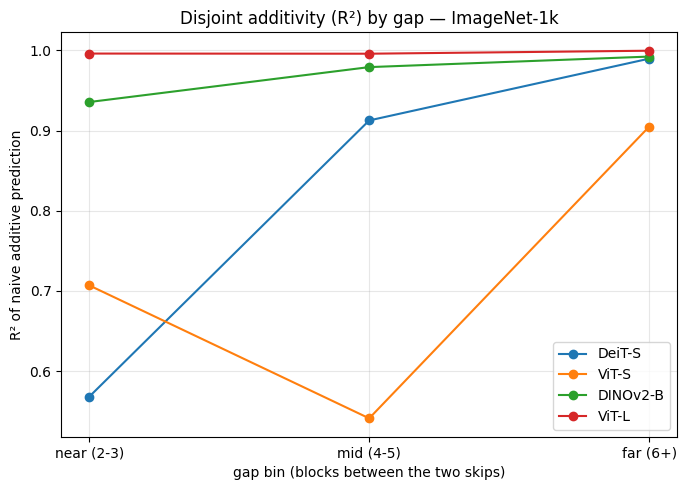

In [83]:
fig, ax = plt.subplots(figsize=(7, 5))
for model, g in gap_stratified.groupby("model", sort=False):
    ax.plot(g["gap_bin"].astype(str), g["r2"], marker="o", label=model)
ax.set_title("Disjoint additivity (R²) by gap — ImageNet-1k")
ax.set_xlabel("gap bin (blocks between the two skips)")
ax.set_ylabel("R² of naive additive prediction")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "s3_disjoint_gap.png", dpi=200, bbox_inches="tight")
plt.show()

For every backbone R² rises from the near to the far bin: the farther apart the two skipped blocks, the closer naive summation gets to exact. The effect is largest for DeiT-S (0.54 → 0.99) and ViT-S (0.67 → 0.91); ViT-L is near-additive at every gap. Pearson stays high in every bin, so near pairs are still ranked well; what breaks down is the magnitude, i.e. close pairs interact. The tercile bins overlap at their edges (e.g. gap 3 sits in both near and mid for the 12-block models) because the split is by rank.

## 4. Illustrative example — ViT-L / ImageNet-1k

Raw accuracy curves behind the numbers above: single-block skips, contiguous 2-block skips, and disjoint skips with exactly one untouched block between them (gap 2).

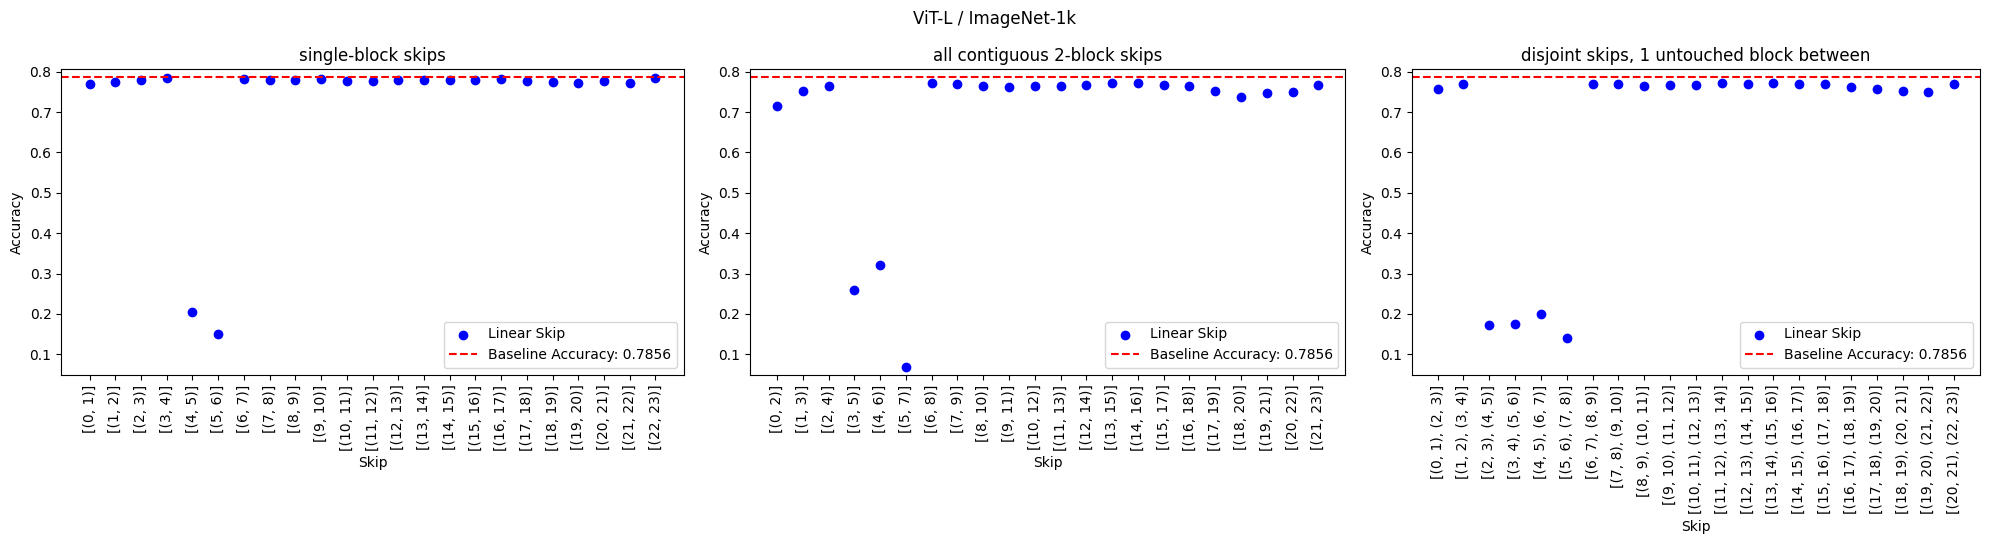

In [84]:
model, dataset = "vitlarge", "imagenet1k"
baseline = baselines[(model, dataset)]


def first_start(spans):
    return min(s for s, _ in spans)


def select(frame, keep=lambda sp: True):
    sel = frame[(frame["model"] == model) & (frame["dataset"] == dataset) & frame["spans"].map(keep)].copy()
    return sel.assign(first=sel["spans"].map(first_start)).sort_values("first")


single = select(single_acc)
contiguous_two = select(contiguous_acc)
gapped = select(disjoint_acc, lambda sp: sorted(sp)[1][0] - sorted(sp)[0][0] == 2)

panels = [
    (single, "single-block skips"),
    (contiguous_two, "all contiguous 2-block skips"),
    (gapped, "disjoint skips, 1 untouched block between"),
]
all_acc = pd.concat([d["accuracy_mean"] for d, _ in panels])
best_val, worst_val = max(all_acc.max(), baseline) + 0.02, all_acc.min() - 0.02

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), width_ratios=[len(d) for d, _ in panels])
fig.suptitle(f"{MODELS[model]} / {DATASETS[dataset]}")

for ax, (data, subtitle) in zip(axes, panels):
    ax.scatter(data["approx_layer"], data["accuracy_mean"], color="blue", label="Linear Skip")
    ax.axhline(y=baseline, color="red", linestyle="--", label=f"Baseline Accuracy: {baseline:.4f}")
    ax.set_title(subtitle)
    ax.set_xlabel("Skip")
    ax.set_ylabel("Accuracy")
    ax.tick_params(axis="x", rotation=90)
    ax.set_ylim(worst_val, best_val)
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "s3_vitlarge_imagenet1k_skips.png", dpi=200, bbox_inches="tight")
plt.show()

## Takeaways

1. **Contiguous 2-block spans (CIFAR-100, ImageNet-1k, 4 backbones)**: naive summation of the two single-skip drops is the most robust predictor; learned local-CKA / angular-distance corrections don't beat it out of sample on any combo by Pearson.
2. **Disjoint pairs (ImageNet-1k, 4 backbones)**: naive summation already predicts and ranks well; cka and angdist corrections are within noise of it.
3. **Stratifying disjoint pairs by gap** shows additivity strengthening with distance for every backbone, i.e. the interaction between skipped blocks decays with separation; this is why disjoint pairs are closer to additive than contiguous spans.

In [85]:
contiguous.assign(shape="contiguous").pipe(lambda c: pd.concat([c, disjoint.assign(shape="disjoint")])) \
    .to_csv(ANALYSIS / "s3_predictor_comparison.csv", index=False)
gap_stratified.to_csv(ANALYSIS / "s3_disjoint_additivity_by_gap.csv", index=False)

NameError: name 'contiguous' is not defined